In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
df = pd.read_csv(r"C:\Users\Erin\Downloads\archive (5)\car data.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [7]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Column names:
['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Driven_kms', 'Fuel_Type', 'Selling_type', 'Transmission', 'Owner']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Selling_type   301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Car_Name,301,98,city,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,301.0,NaN,NaN,NaN,2013.627907,2.891554,2003.0,2012.0,2014.0,2016.0,2018.0
Selling_Price,301.0,NaN,NaN,NaN,4.661296,5.082812,0.1,0.9,3.6,6.0,35.0
Present_Price,301.0,NaN,NaN,NaN,7.628472,8.642584,0.32,1.2,6.4,9.9,92.6
Driven_kms,301.0,NaN,NaN,NaN,36947.20598,38886.883882,500.0,15000.0,32000.0,48767.0,500000.0
Fuel_Type,301,3,Petrol,239,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Selling_type,301,2,Dealer,195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transmission,301,2,Manual,261,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Owner,301.0,NaN,NaN,NaN,0.043189,0.247915,0.0,0.0,0.0,0.0,3.0



Missing values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64

Duplicate rows: 2


In [10]:
print(df.columns.tolist())

['car_name', 'year', 'selling_price', 'present_price', 'driven_kms', 'fuel_type', 'selling_type', 'transmission', 'owner']


In [11]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(df.columns.tolist())

['car_name', 'year', 'selling_price', 'present_price', 'driven_kms', 'fuel_type', 'selling_type', 'transmission', 'owner']


In [12]:
df["selling_price"] = pd.to_numeric(
    df["selling_price"], errors="coerce"
)

df = df.dropna(subset=["selling_price"])
df = df[df["selling_price"] > 0].copy()

In [15]:

# Normalize column names
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

# Replace invalid markers with missing values
df = df.replace("?", np.nan)

# Remove duplicate records
df = df.drop_duplicates()

# Identify target price column
possible_targets = [
    "price",
    "selling_price",
    "sellingprice",
    "msrp",
    "present_price"
]

target_col = next(
    (col for col in possible_targets if col in df.columns),
    None
)

if target_col is None:
    print("Price column not found!")
    print("Available columns:", df.columns.tolist())
else:
    df[target_col] = pd.to_numeric(
        df[target_col], errors="coerce"
    )

    df = df.dropna(subset=[target_col])
    df = df[df[target_col] > 0].copy()

    print("Data cleaning completed!")
    print("Target column:", target_col)
    print("Cleaned shape:", df.shape)
    display(df.head())

Data cleaning completed!
Target column: selling_price
Cleaned shape: (299, 9)


,car_name,year,selling_price,present_price,driven_kms,fuel_type,selling_type,transmission,owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [17]:
# Feature engineering

# Extract brand only if a car-name column exists
name_col = next(
    (col for col in ["carname", "name", "car_name", "CarName".lower()]
     if col in df.columns),
    None
)

if name_col:
    df["brand"] = (
        df[name_col]
        .astype(str)
        .str.lower()
        .str.split()
        .str[0]
    )
    print("Brand extracted from:", name_col)
else:
    print("No car-name column found. Brand feature skipped.")

# Create average mileage only if both columns exist
if "citympg" in df.columns and "highwaympg" in df.columns:
    df["average_mpg"] = (
        df["citympg"] + df["highwaympg"]
    ) / 2
    print("Average MPG created.")
elif "mileage" in df.columns:
    print("Existing mileage column found.")
else:
    print("Mileage columns not found; check dataset column names.")

display(df.head())

Brand extracted from: car_name
Mileage columns not found; check dataset column names.


,car_name,year,selling_price,present_price,driven_kms,fuel_type,selling_type,transmission,owner,brand
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0,ritz
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0,sx4
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0,ciaz
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0,wagon
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0,swift


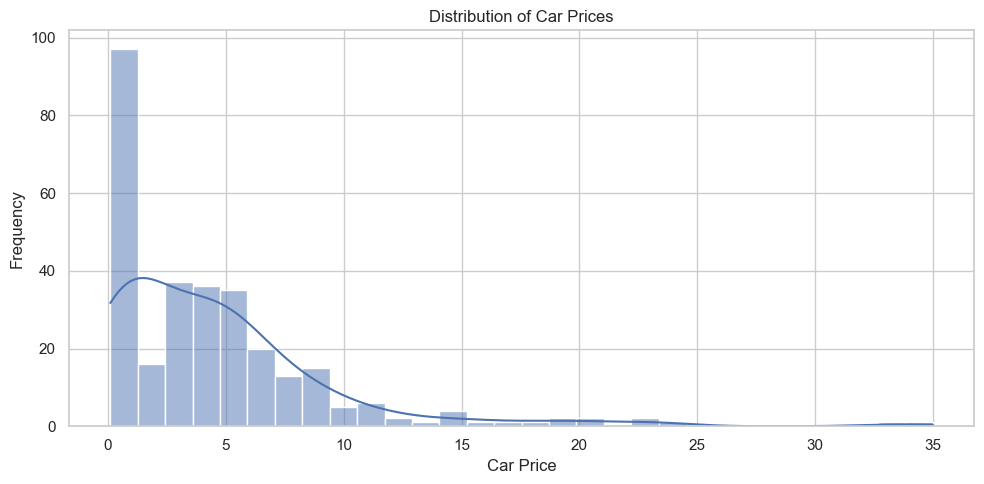

In [19]:
plt.figure(figsize=(10, 5))

sns.histplot(df[target_col], kde=True, bins=30)

plt.title("Distribution of Car Prices")
plt.xlabel("Car Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

Numerical features: ['year', 'present_price', 'driven_kms', 'owner']


,Correlation with Price
present_price,0.876305
year,0.234369
driven_kms,0.028566
owner,-0.087880


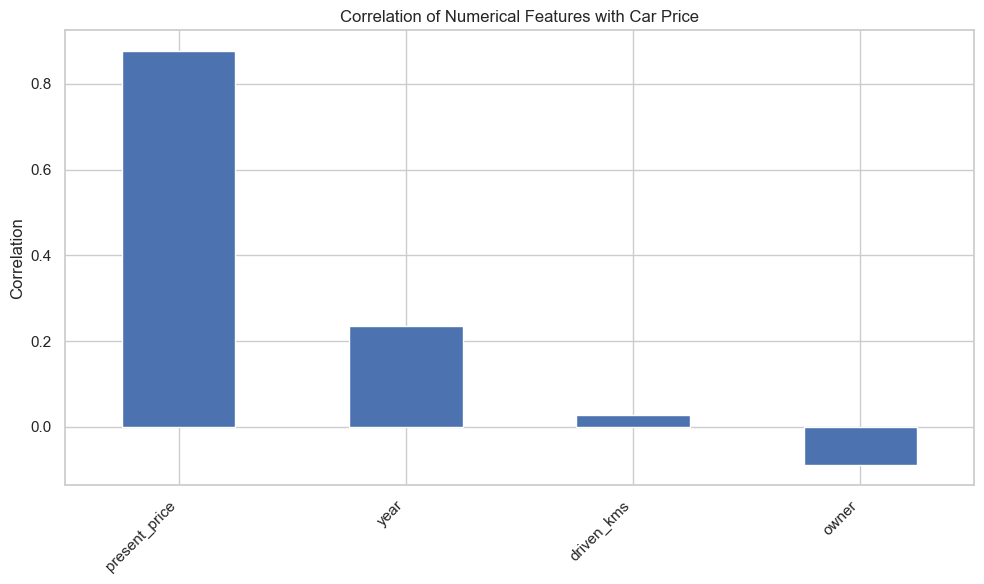

In [20]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

# Exclude target from predictor list
numeric_features = [col for col in numeric_cols if col != target_col]

print("Numerical features:", numeric_features)

# Display correlation with target
if numeric_features:
    correlations = (
        df[numeric_features + [target_col]]
        .corr(numeric_only=True)[target_col]
        .drop(target_col)
        .sort_values(ascending=False)
    )

    display(correlations.to_frame("Correlation with Price"))

    plt.figure(figsize=(10, 6))
    correlations.plot(kind="bar")
    plt.title("Correlation of Numerical Features with Car Price")
    plt.ylabel("Correlation")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

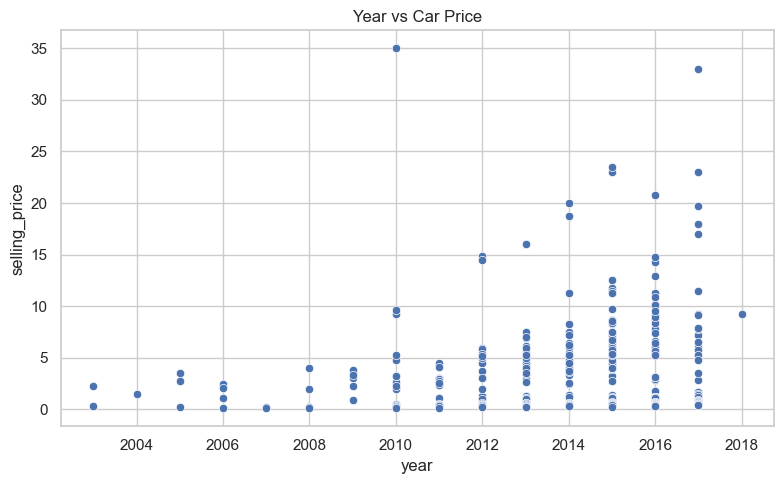

In [21]:
preferred_features = [
    "horsepower", "average_mpg", "citympg",
    "highwaympg", "enginesize", "km_driven",
    "mileage", "year", "curbweight"
]

available_features = [
    col for col in preferred_features if col in df.columns
]

for col in available_features[:4]:
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=df, x=col, y=target_col)
    plt.title(f"{col.replace('_', ' ').title()} vs Car Price")
    plt.tight_layout()
    plt.show()

,Average Price
brand,
land,35.00
fortuner,18.25
innova,12.78
creta,11.80
elantra,11.60
vitara,9.25
ciaz,7.47
city,7.42
corolla,6.85


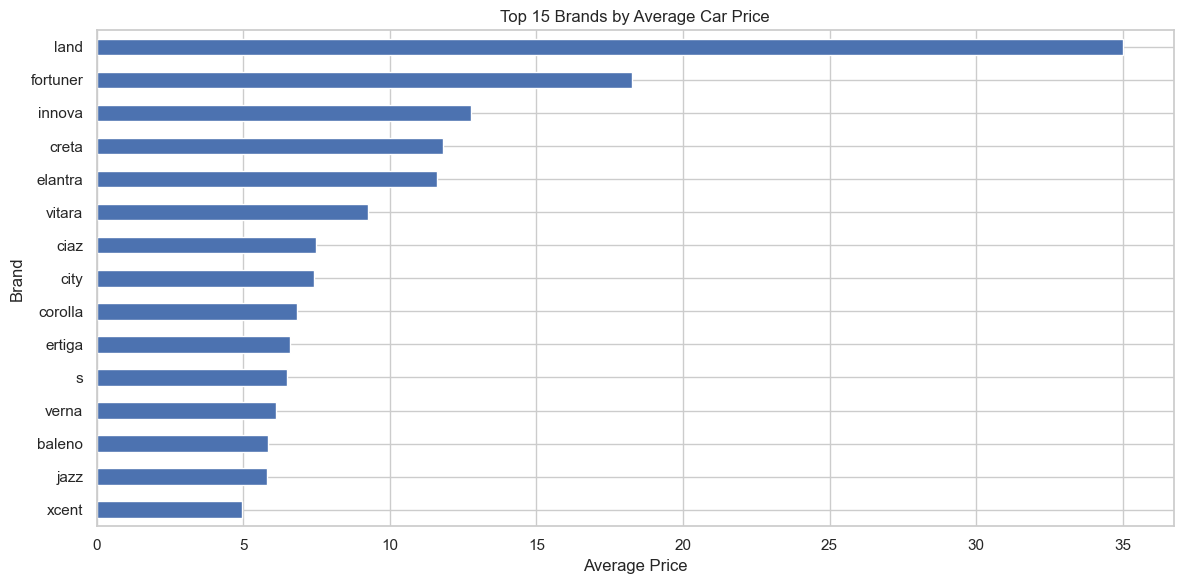

In [22]:
if "brand" in df.columns:
    brand_prices = (
        df.groupby("brand")[target_col]
        .mean()
        .sort_values(ascending=False)
    )

    display(brand_prices.to_frame("Average Price").round(2))

    plt.figure(figsize=(12, 6))
    brand_prices.head(15).sort_values().plot(kind="barh")

    plt.title("Top 15 Brands by Average Car Price")
    plt.xlabel("Average Price")
    plt.ylabel("Brand")
    plt.tight_layout()
    plt.show()
else:
    print("Brand column not available; skipping brand analysis.")

In [23]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=[target_col])
y = df[target_col]

# Remove identifier columns if present
X = X.drop(
    columns=["car_id", "id", "unnamed_0"],
    errors="ignore"
)

# Drop columns that contain only missing values
X = X.dropna(axis=1, how="all")

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Numerical features: ['year', 'present_price', 'driven_kms', 'owner']
Categorical features: ['car_name', 'fuel_type', 'selling_type', 'transmission', 'brand']
Training samples: 239
Testing samples: 60


In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [25]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

results = []
trained_models = {}

for name, regressor in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", regressor)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results).sort_values(
    "R2 Score", ascending=False
).reset_index(drop=True)

display(results_df.round(3))

,Model,MAE,RMSE,R2 Score
0,Ridge Regression,1.336,2.432,0.771
1,Linear Regression,1.419,2.639,0.730
2,Gradient Boosting,1.172,2.676,0.722
3,Random Forest,1.351,3.231,0.595


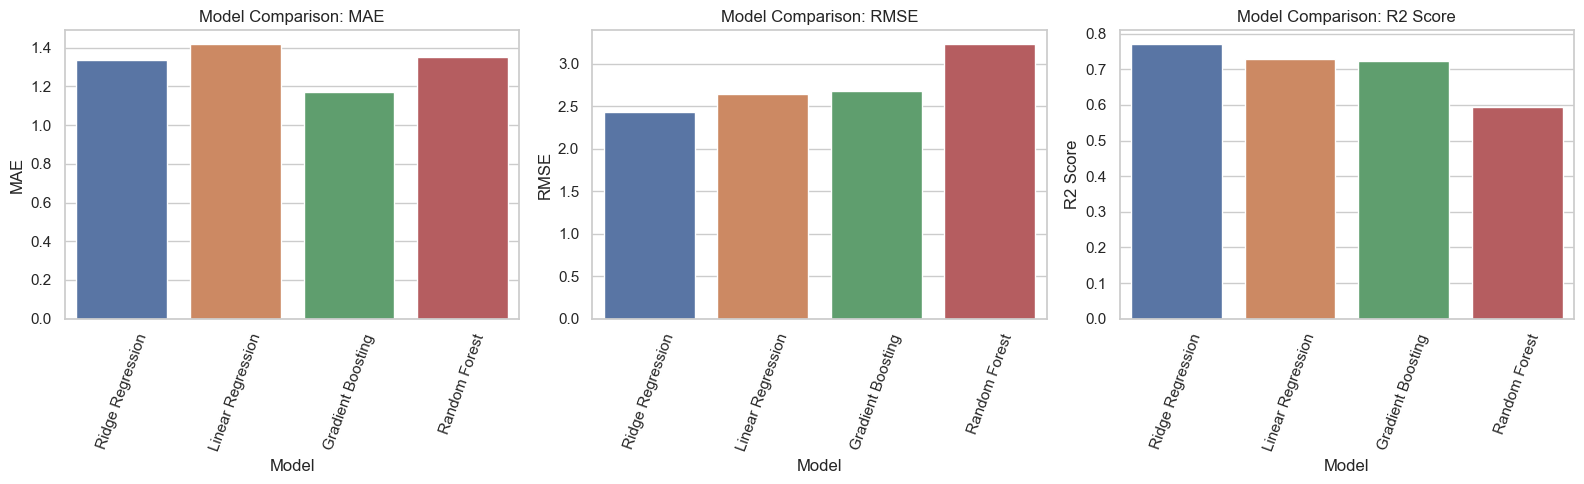

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric in zip(axes, ["MAE", "RMSE", "R2 Score"]):
    sns.barplot(
        data=results_df,
        x="Model",
        y=metric,
        hue="Model",
        legend=False,
        ax=ax
    )
    ax.set_title(f"Model Comparison: {metric}")
    ax.tick_params(axis="x", rotation=70)

plt.tight_layout()
plt.show()

Best model: Ridge Regression
R2 Score: 0.771


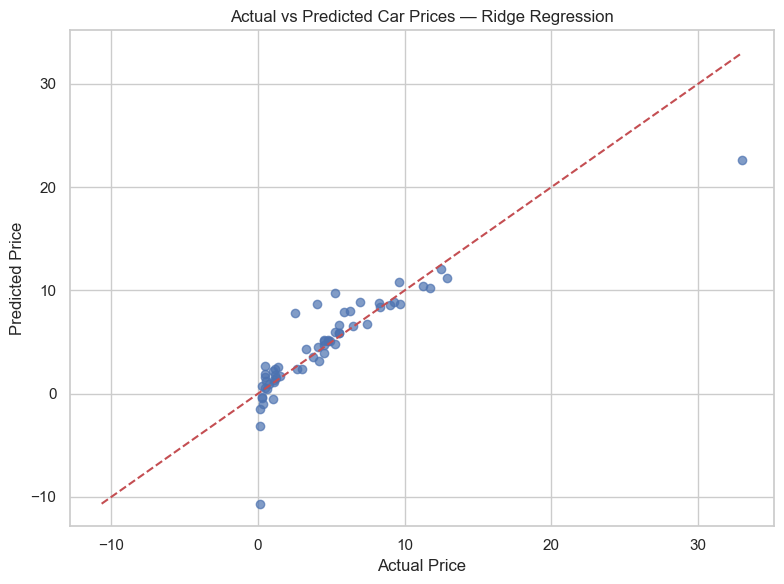

In [27]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

best_predictions = best_model.predict(X_test)

print("Best model:", best_model_name)
print("R2 Score:", round(r2_score(y_test, best_predictions), 3))

plt.figure(figsize=(8, 6))

plt.scatter(y_test, best_predictions, alpha=0.7)

min_val = min(y_test.min(), best_predictions.min())
max_val = max(y_test.max(), best_predictions.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title(f"Actual vs Predicted Car Prices — {best_model_name}")
plt.tight_layout()
plt.show()

,Feature,Importance
2,present_price,0.798250
1,year,0.133447
4,fuel_type,0.026769
6,transmission,0.025202
0,car_name,0.021762
5,selling_type,0.012085
8,brand,0.007050
3,driven_kms,0.003608
7,owner,-0.004269


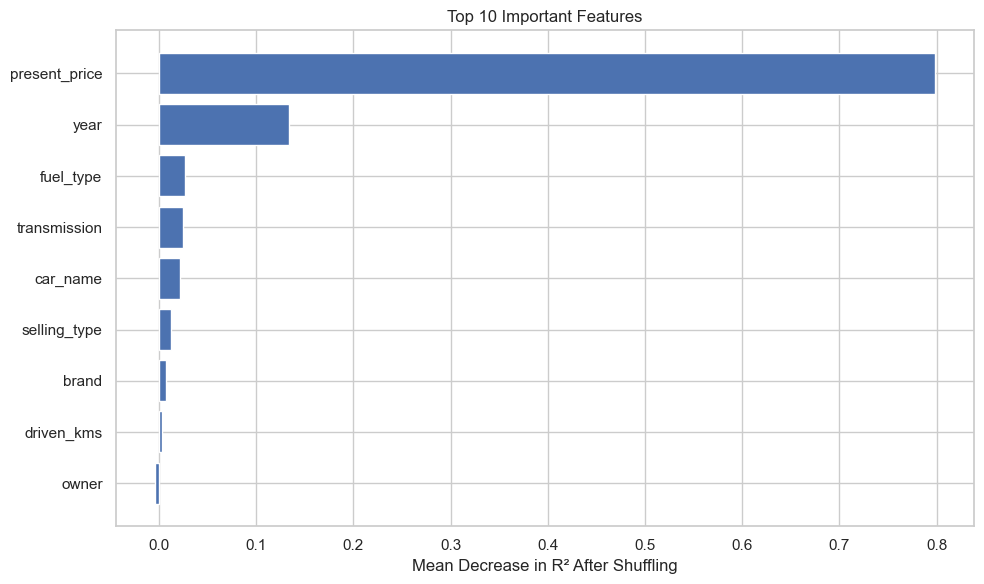

In [28]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="r2",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean
}).sort_values("Importance", ascending=False)

display(importance_df.head(10))

top_features = importance_df.head(10).sort_values("Importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])

plt.title("Top 10 Important Features")
plt.xlabel("Mean Decrease in R² After Shuffling")
plt.tight_layout()
plt.show()

In [29]:
from sklearn.model_selection import cross_val_score

cv_results = []

for name, regressor in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", regressor)
    ])

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=5,
        scoring="r2"
    )

    cv_results.append({
        "Model": name,
        "Mean CV R2": scores.mean(),
        "Standard Deviation": scores.std()
    })

cv_df = pd.DataFrame(cv_results).sort_values(
    "Mean CV R2", ascending=False
)

display(cv_df.round(3))

,Model,Mean CV R2,Standard Deviation
2,Random Forest,0.895,0.096
3,Gradient Boosting,0.876,0.115
1,Ridge Regression,0.863,0.075
0,Linear Regression,0.848,0.074


This project applies machine learning regression techniques to predict car prices based on available vehicle features. Data preprocessing, feature engineering, exploratory data analysis, model comparison, and evaluation using MAE, RMSE, and R² were performed. The project demonstrates how price prediction models can support used-car valuation, automotive marketplaces, and preliminary pricing decisions. Predictions depend on dataset quality and may not fully reflect real-world factors such as vehicle condition, location, maintenance history, and changing market demand.